In [1]:
import pandas as pd
import numpy as np
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def sigbar(x1, x2, y, p, fontsize = 10, lw = 1.5):

    plt.hlines(y, x1, x2, lw = lw, colors = 'k')
    if p < 0.001: text = '***'
    elif p < 0.01: text = '**'
    elif p < 0.05: text = '*'
    else: text = 'n.s.'
    plt.text(x = (x1+x2)/2, y = y, s = text, fontsize = fontsize, ha = 'center', va = 'bottom')

In [3]:
res_r = pd.read_csv('../results/fig05/validation_res_HCP_MMP(distance_ridge).csv'); res_r['FILE_ID'] = res_r['FILE_ID'].astype(str)
summary_r = res_r.drop(columns = ['FILE_ID']).groupby('lambda').agg(['mean', 'std'])['R2_5fold(raw)']
res_m = pd.read_csv('../results/fig05/validation_res_HCP_motor_MMP(distance_ridge).csv'); res_m['FILE_ID'] = res_m['FILE_ID'].astype(str)
summary_m = res_m.drop(columns = ['FILE_ID']).groupby('lambda').agg(['mean', 'std'])['R2_5fold(raw)']

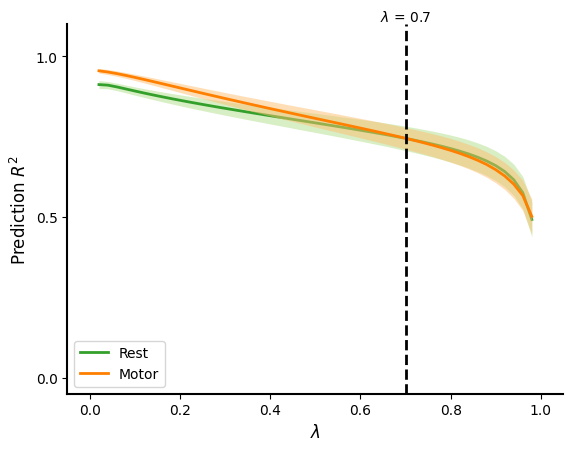

In [4]:
plt.figure(figsize = (6.4, 4.8))
plt.plot(summary_r.index, summary_r['mean'].values, c = sns.color_palette('Paired')[3], linewidth = 2, zorder = 2, label = 'Rest')
plt.fill_between(summary_r.index, summary_r['mean'].values-summary_r['std'].values, summary_r['mean'].values+summary_r['std'].values, color = sns.color_palette('Paired')[2], lw = 0, alpha = 0.5, zorder = 1)
plt.plot(summary_m.index, summary_m['mean'].values, c = sns.color_palette('Paired')[7], linewidth = 2, zorder = 4, label = 'Motor')
plt.fill_between(summary_m.index, summary_m['mean'].values-summary_m['std'].values, summary_m['mean'].values+summary_m['std'].values, color = sns.color_palette('Paired')[6], lw = 0, alpha = 0.5, zorder = 3)
plt.vlines(0.7, ymin = -0.05, ymax = 1.10, color = 'k', linestyle = '--', linewidth = 2, zorder = 5)
plt.text(x = 0.7, y = 1.10, s = r'$\lambda$ = 0.7', ha = 'center', va = 'bottom', fontsize = 10)

plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(1.5); plt.gca().spines['bottom'].set_linewidth(1.5)
plt.xlabel(r'$\lambda$', fontsize = 12); plt.xlim(-0.05, 1.05); plt.xticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0], fontsize = 10)
plt.ylabel(r'Prediction $R^2$', fontsize = 12); plt.ylim(-0.05, 1.10); plt.yticks([0.0, 0.5, 1.0], fontsize = 10)
plt.legend(loc = 'lower left', fontsize = 10)

plt.show()

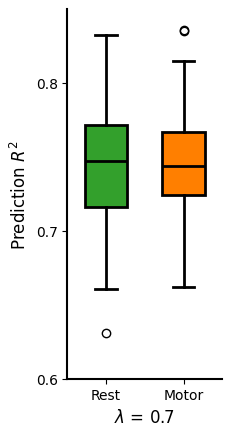

In [5]:
plt.figure(figsize = (2.0, 4.8))
box = plt.gca().boxplot([res_r[abs(res_r['lambda'] - 0.7) < 1e-3]['R2_5fold(raw)'].values, res_m[abs(res_m['lambda'] - 0.7) < 1e-3]['R2_5fold(raw)'].values], patch_artist = True, widths = 0.55)
for patch, color in zip(box['boxes'], [sns.color_palette('Paired')[3], sns.color_palette('Paired')[7]]): patch.set_facecolor(color)
for i in range(2):
    box['boxes'][i].set_linewidth(2)
    box['medians'][i].set_color('k'); box['medians'][i].set_linewidth(2)
    box['whiskers'][2*i].set_linewidth(2); box['caps'][2*i].set_linewidth(2)
    box['whiskers'][2*i+1].set_linewidth(2); box['caps'][2*i+1].set_linewidth(2)

plt.xlabel(r'$\lambda$ = 0.7', fontsize = 12); plt.xlim(0.5, 2.5); plt.xticks([1, 2], ['Rest', 'Motor'], fontsize = 10)
plt.ylabel(r'Prediction $R^2$', fontsize = 12); plt.ylim(0.6, 0.85); plt.yticks([0.6, 0.7, 0.8], fontsize = 10)
plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(1.5); plt.gca().spines['bottom'].set_linewidth(1.5)

plt.show()

In [6]:
res_r = pd.read_csv('../results/fig05/validation_res_HCP_MMP(distance_ridge).csv'); res_r['FILE_ID'] = res_r['FILE_ID'].astype(str)
summary_r = res_r.drop(columns = ['FILE_ID']).groupby('lambda').agg(['mean', 'std'])['SC_corr']
res_m = pd.read_csv('../results/fig05/validation_res_HCP_motor_MMP(distance_ridge).csv'); res_m['FILE_ID'] = res_m['FILE_ID'].astype(str)
summary_m = res_m.drop(columns = ['FILE_ID']).groupby('lambda').agg(['mean', 'std'])['SC_corr']

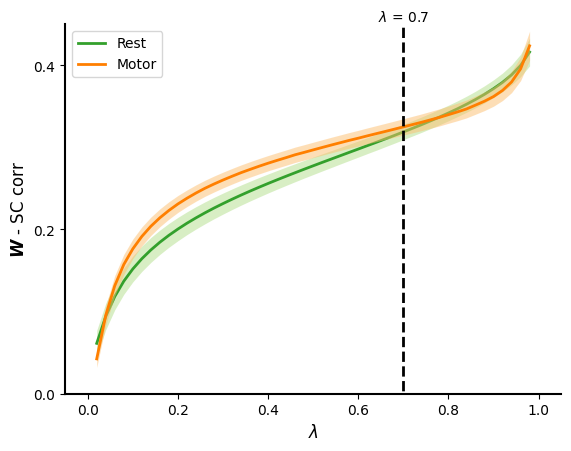

In [7]:
plt.figure(figsize = (6.4, 4.8))
plt.plot(summary_r.index, summary_r['mean'].values, c = sns.color_palette('Paired')[3], linewidth = 2, zorder = 2, label = 'Rest')
plt.fill_between(summary_r.index, summary_r['mean'].values-summary_r['std'].values, summary_r['mean'].values+summary_r['std'].values, color = sns.color_palette('Paired')[2], lw = 0, alpha = 0.5, zorder = 1)
plt.plot(summary_m.index, summary_m['mean'].values, c = sns.color_palette('Paired')[7], linewidth = 2, zorder = 4, label = 'Motor')
plt.fill_between(summary_m.index, summary_m['mean'].values-summary_m['std'].values, summary_m['mean'].values+summary_m['std'].values, color = sns.color_palette('Paired')[6], lw = 0, alpha = 0.5, zorder = 3)
plt.vlines(0.7, ymin = -0.05, ymax = 1.10, color = 'k', linestyle = '--', linewidth = 2, zorder = 5)
plt.text(x = 0.7, y = 0.45, s = r'$\lambda$ = 0.7', ha = 'center', va = 'bottom', fontsize = 10)

plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(1.5); plt.gca().spines['bottom'].set_linewidth(1.5)
plt.xlabel(r'$\lambda$', fontsize = 12); plt.xlim(-0.05, 1.05); plt.xticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0], fontsize = 10)
plt.ylabel(r'$\boldsymbol{W}$ - SC corr', fontsize = 12); plt.ylim(0.0, 0.45); plt.yticks([0.0, 0.2, 0.4], fontsize = 10)
plt.legend(loc = 'upper left', fontsize = 10)

plt.show()

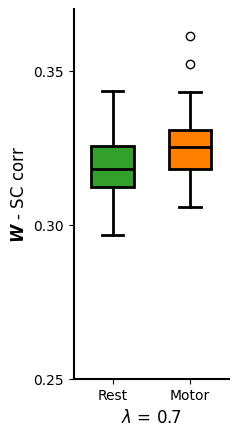

In [8]:
plt.figure(figsize = (2.0, 4.8))
box = plt.gca().boxplot([res_r[abs(res_r['lambda'] - 0.7) < 1e-3]['SC_corr'].values, res_m[abs(res_m['lambda'] - 0.7) < 1e-3]['SC_corr'].values], patch_artist = True, widths = 0.55)
for patch, color in zip(box['boxes'], [sns.color_palette('Paired')[3], sns.color_palette('Paired')[7]]): patch.set_facecolor(color)
for i in range(2):
    box['boxes'][i].set_linewidth(2)
    box['medians'][i].set_color('k'); box['medians'][i].set_linewidth(2)
    box['whiskers'][2*i].set_linewidth(2); box['caps'][2*i].set_linewidth(2)
    box['whiskers'][2*i+1].set_linewidth(2); box['caps'][2*i+1].set_linewidth(2)

plt.xlabel(r'$\lambda$ = 0.7', fontsize = 12); plt.xlim(0.5, 2.5); plt.xticks([1, 2], ['Rest', 'Motor'], fontsize = 10)
plt.ylabel(r'$\boldsymbol{W}$ - SC corr', fontsize = 12); plt.ylim(0.25, 0.37); plt.yticks([0.25, 0.30, 0.35], fontsize = 10)
plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(1.5); plt.gca().spines['bottom'].set_linewidth(1.5)

plt.show()

In [9]:
res_r = pd.read_csv('../results/fig05/graphical_res_HCP_MMP(distance_ridge).csv')
summary_r = res_r[(res_r['lambda'] > 0.1-1e-3) & (res_r['lambda'] < 0.9+1e-3)].drop(columns = ['FILE_ID']).groupby('lambda').agg(['mean', 'std'])['global_cost']
res_m = pd.read_csv('../results/fig05/graphical_res_HCP_motor_MMP(distance_ridge).csv')
summary_m = res_m[(res_m['lambda'] > 0.1-1e-3) & (res_m['lambda'] < 0.9+1e-3)].drop(columns = ['FILE_ID']).groupby('lambda').agg(['mean', 'std'])['global_cost']

pval = wilcoxon(res_r[abs(res_r['lambda'] - 0.7) < 1e-3]['global_cost'].values,  res_m[abs(res_m['lambda'] - 0.7) < 1e-3]['global_cost'].values)[1]
if pval < 0.001: text = '***'
elif pval < 0.01: text = '**'
elif pval < 0.05: text = '*'
else: text = 'n.s.'

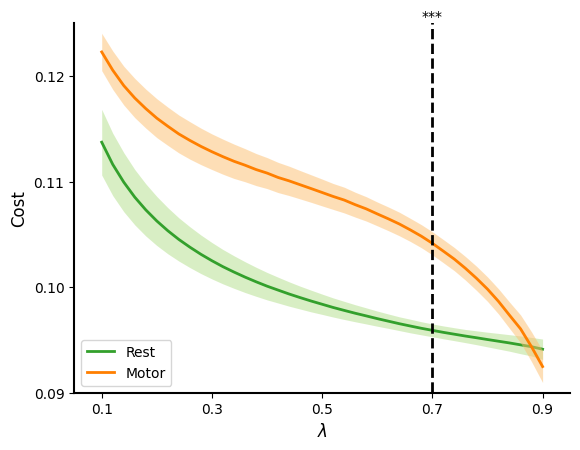

In [10]:
plt.plot(summary_r.index, summary_r['mean'].values, c = sns.color_palette('Paired')[3], linewidth = 2, zorder = 2, label = 'Rest')
plt.fill_between(summary_r.index, summary_r['mean'].values-summary_r['std'].values, summary_r['mean'].values+summary_r['std'].values, color = sns.color_palette('Paired')[2], lw = 0, alpha = 0.5, zorder = 1)
plt.plot(summary_m.index, summary_m['mean'].values, c = sns.color_palette('Paired')[7], linewidth = 2, zorder = 4, label = 'Motor')
plt.fill_between(summary_m.index, summary_m['mean'].values-summary_m['std'].values, summary_m['mean'].values+summary_m['std'].values, color = sns.color_palette('Paired')[6], lw = 0, alpha = 0.5, zorder = 3)
plt.vlines(0.7, ymin = -0.05, ymax = 1.10, color = 'k', linestyle = '--', linewidth = 2, zorder = 5)
plt.text(x = 0.7, y = 0.125, s = text, ha = 'center', va = 'bottom')

plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(1.5); plt.gca().spines['bottom'].set_linewidth(1.5)
plt.xlabel(r'$\lambda$', fontsize = 12); plt.xlim(0.050, 0.950); plt.xticks([0.1, 0.3, 0.5, 0.7, 0.9], fontsize = 10)
plt.ylabel('Cost', fontsize = 12); plt.ylim(0.090, 0.125); plt.yticks([0.09, 0.10, 0.11, 0.12], fontsize = 10)
plt.legend(loc = 'lower left', fontsize = 10)

plt.show()

In [11]:
res_r = pd.read_csv('../results/fig05/graphical_res_HCP_MMP(distance_ridge).csv')
summary_r = res_r[(res_r['lambda'] > 0.1-1e-3) & (res_r['lambda'] < 0.9+1e-3)].drop(columns = ['FILE_ID']).groupby('lambda').agg(['mean', 'std'])['global_effi']
res_m = pd.read_csv('../results/fig05/graphical_res_HCP_motor_MMP(distance_ridge).csv')
summary_m = res_m[(res_m['lambda'] > 0.1-1e-3) & (res_m['lambda'] < 0.9+1e-3)].drop(columns = ['FILE_ID']).groupby('lambda').agg(['mean', 'std'])['global_effi']

pval = wilcoxon(res_r[abs(res_r['lambda'] - 0.7) < 1e-3]['global_effi'].values,  res_m[abs(res_m['lambda'] - 0.7) < 1e-3]['global_effi'].values)[1]
if pval < 0.001: text = '***'
elif pval < 0.01: text = '**'
elif pval < 0.05: text = '*'
else: text = 'n.s.'

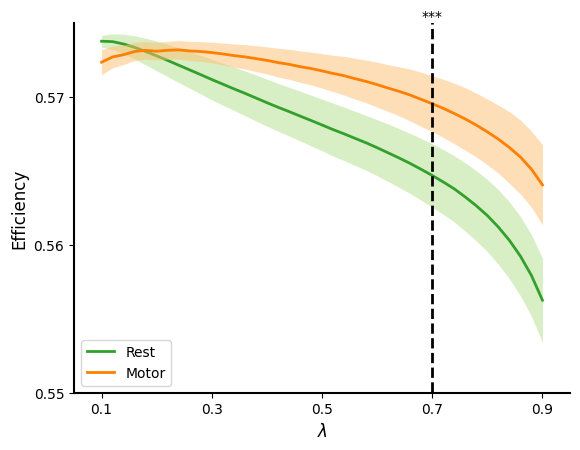

In [12]:
plt.plot(summary_r.index, summary_r['mean'].values, c = sns.color_palette('Paired')[3], linewidth = 2, zorder = 2, label = 'Rest')
plt.fill_between(summary_r.index, summary_r['mean'].values-summary_r['std'].values, summary_r['mean'].values+summary_r['std'].values, color = sns.color_palette('Paired')[2], lw = 0, alpha = 0.5, zorder = 1)
plt.plot(summary_m.index, summary_m['mean'].values, c = sns.color_palette('Paired')[7], linewidth = 2, zorder = 4, label = 'Motor')
plt.fill_between(summary_m.index, summary_m['mean'].values-summary_m['std'].values, summary_m['mean'].values+summary_m['std'].values, color = sns.color_palette('Paired')[6], lw = 0, alpha = 0.5, zorder = 3)
plt.vlines(0.7, ymin = -0.05, ymax = 1.10, color = 'k', linestyle = '--', linewidth = 2, zorder = 5)
plt.text(x = 0.7, y = 0.575, s = text, ha = 'center', va = 'bottom')

plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(1.5); plt.gca().spines['bottom'].set_linewidth(1.5)
plt.xlabel(r'$\lambda$', fontsize = 12); plt.xlim(0.050, 0.950); plt.xticks([0.1, 0.3, 0.5, 0.7, 0.9], fontsize = 10)
plt.ylabel('Efficiency', fontsize = 12); plt.ylim(0.550, 0.575); plt.yticks([0.55, 0.56, 0.57], fontsize = 10)
plt.legend(loc = 'lower left', fontsize = 10)

plt.show()

In [13]:
res_r = pd.read_csv('../results/fig05/graphical_res_HCP_MMP(distance_ridge).csv')
res_m = pd.read_csv('../results/fig05/graphical_res_HCP_motor_MMP(distance_ridge).csv')

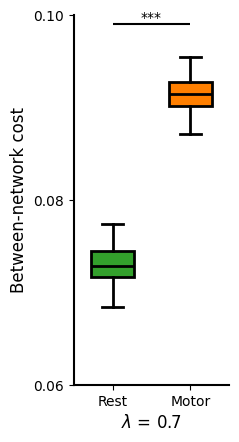

In [14]:
metric = 'inter_cost'

plt.figure(figsize = (2.0, 4.8))
box = plt.gca().boxplot([res_r[abs(res_r['lambda'] - 0.7) < 1e-3][metric].values, res_m[abs(res_m['lambda'] - 0.7) < 1e-3][metric].values], patch_artist = True, widths = 0.55)
for patch, color in zip(box['boxes'], [sns.color_palette('Paired')[3], sns.color_palette('Paired')[7]]): patch.set_facecolor(color)
for i in range(2):
    box['boxes'][i].set_linewidth(2)
    box['medians'][i].set_color('k'); box['medians'][i].set_linewidth(2)
    box['whiskers'][2*i].set_linewidth(2); box['caps'][2*i].set_linewidth(2)
    box['whiskers'][2*i+1].set_linewidth(2); box['caps'][2*i+1].set_linewidth(2)
pval = wilcoxon(res_r[abs(res_r['lambda'] - 0.7) < 1e-3][metric].values,  res_m[abs(res_m['lambda'] - 0.7) < 1e-3][metric].values)[1]
sigbar(1, 2, 0.099, pval)

plt.xlabel(r'$\lambda$ = 0.7', fontsize = 12); plt.xlim(0.5, 2.5); plt.xticks([1, 2], ['Rest', 'Motor'], fontsize = 10)
plt.ylabel('Between-network cost', fontsize = 12); plt.ylim(0.06, 0.10); plt.yticks([0.06, 0.08, 0.10], fontsize = 10)
plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(1.5); plt.gca().spines['bottom'].set_linewidth(1.5)

plt.show()

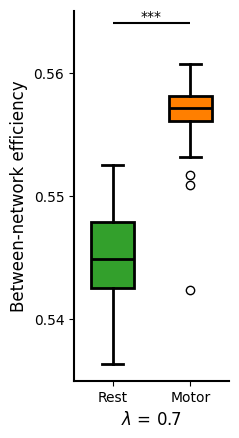

In [15]:
metric = 'inter_effi'

plt.figure(figsize = (2.0, 4.8))
box = plt.gca().boxplot([res_r[abs(res_r['lambda'] - 0.7) < 1e-3][metric].values, res_m[abs(res_m['lambda'] - 0.7) < 1e-3][metric].values], patch_artist = True, widths = 0.55)
for patch, color in zip(box['boxes'], [sns.color_palette('Paired')[3], sns.color_palette('Paired')[7]]): patch.set_facecolor(color)
for i in range(2):
    box['boxes'][i].set_linewidth(2)
    box['medians'][i].set_color('k'); box['medians'][i].set_linewidth(2)
    box['whiskers'][2*i].set_linewidth(2); box['caps'][2*i].set_linewidth(2)
    box['whiskers'][2*i+1].set_linewidth(2); box['caps'][2*i+1].set_linewidth(2)
pval = wilcoxon(res_r[abs(res_r['lambda'] - 0.7) < 1e-3][metric].values,  res_m[abs(res_m['lambda'] - 0.7) < 1e-3][metric].values)[1]
sigbar(1, 2, 0.564, pval)

plt.xlabel(r'$\lambda$ = 0.7', fontsize = 12); plt.xlim(0.5, 2.5); plt.xticks([1, 2], ['Rest', 'Motor'], fontsize = 10)
plt.ylabel('Between-network efficiency', fontsize = 12); plt.ylim(0.535, 0.565); plt.yticks([0.54, 0.55, 0.56], fontsize = 10)
plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(1.5); plt.gca().spines['bottom'].set_linewidth(1.5)

plt.show()

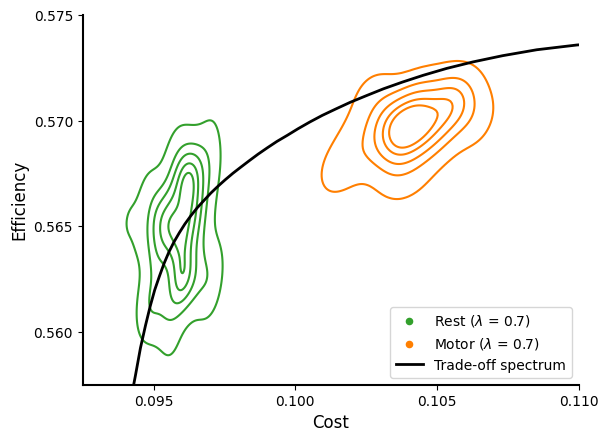

In [16]:
res_r = pd.read_csv('../results/fig05/graphical_res_HCP_MMP(distance_ridge).csv')
res_m = pd.read_csv('../results/fig05/graphical_res_HCP_motor_MMP(distance_ridge).csv')

res = {'task': [], 'cost': [], 'effi': []}
res['task'] += ['rest' for _ in range(100)]; res['cost'] += list(res_r[abs(res_r['lambda'] - 0.7) < 1e-3]['global_cost'].values); res['effi'] += list(res_r[abs(res_r['lambda'] - 0.7) < 1e-3]['global_effi'].values)
res['task'] += ['motor' for _ in range(100)]; res['cost'] += list(res_m[abs(res_m['lambda'] - 0.7) < 1e-3]['global_cost'].values); res['effi'] += list(res_m[abs(res_m['lambda'] - 0.7) < 1e-3]['global_effi'].values)
res = pd.DataFrame(res)
sns.kdeplot(data = res, x = 'cost', y = 'effi', hue = 'task', palette = [sns.color_palette('Paired')[3], sns.color_palette('Paired')[7]], levels = 6, legend = False)
plt.scatter(np.nan, np.nan, s = 20, color = sns.color_palette('Paired')[3], label = r'Rest ($\lambda$ = 0.7)')
plt.scatter(np.nan, np.nan, s = 20, color = sns.color_palette('Paired')[7], label = r'Motor ($\lambda$ = 0.7)')
plt.plot(
    [np.mean(res_r[abs(res_r['lambda'] - lam) < 1e-3]['global_cost'].values) for lam in np.linspace(0.10, 0.98, 45)], 
    [np.mean(res_r[abs(res_r['lambda'] - lam) < 1e-3]['global_effi'].values) for lam in np.linspace(0.10, 0.98, 45)], 
    color = 'k', linewidth = 2, label = 'Trade-off spectrum'
)

plt.xlabel('Cost', fontsize = 12); plt.xlim(0.0925, 0.1100); plt.xticks([0.095, 0.100, 0.105, 0.110], fontsize = 10)
plt.ylabel('Efficiency', fontsize = 12); plt.ylim(0.5575, 0.5750); plt.yticks([0.560, 0.565, 0.570, 0.575], fontsize = 10)
plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(1.5); plt.gca().spines['bottom'].set_linewidth(1.5)
plt.legend(loc = 'lower right', fontsize = 10)

plt.show()

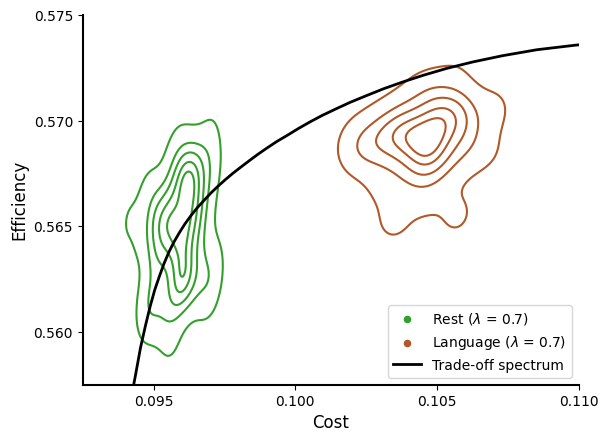

In [17]:
res_r = pd.read_csv('../results/fig05/graphical_res_HCP_MMP(distance_ridge).csv')
res_l = pd.read_csv('../results/fig05/graphical_res_HCP_language_MMP(distance_ridge).csv')

res = {'task': [], 'cost': [], 'effi': []}
res['task'] += ['rest' for _ in range(100)]; res['cost'] += list(res_r[abs(res_r['lambda'] - 0.7) < 1e-3]['global_cost'].values); res['effi'] += list(res_r[abs(res_r['lambda'] - 0.7) < 1e-3]['global_effi'].values)
res['task'] += ['motor' for _ in range(100)]; res['cost'] += list(res_l[abs(res_l['lambda'] - 0.7) < 1e-3]['global_cost'].values); res['effi'] += list(res_l[abs(res_l['lambda'] - 0.7) < 1e-3]['global_effi'].values)
res = pd.DataFrame(res)
sns.kdeplot(data = res, x = 'cost', y = 'effi', hue = 'task', palette = [sns.color_palette('Paired')[3], sns.color_palette('Paired')[11]], levels = 6, legend = False)
plt.scatter(np.nan, np.nan, s = 20, color = sns.color_palette('Paired')[ 3], label = r'Rest ($\lambda$ = 0.7)')
plt.scatter(np.nan, np.nan, s = 20, color = sns.color_palette('Paired')[11], label = r'Language ($\lambda$ = 0.7)')
plt.plot(
    [np.mean(res_r[abs(res_r['lambda'] - lam) < 1e-3]['global_cost'].values) for lam in np.linspace(0.10, 0.98, 45)], 
    [np.mean(res_r[abs(res_r['lambda'] - lam) < 1e-3]['global_effi'].values) for lam in np.linspace(0.10, 0.98, 45)], 
    color = 'k', linewidth = 2, label = 'Trade-off spectrum'
)

plt.xlabel('Cost', fontsize = 12); plt.xlim(0.0925, 0.1100); plt.xticks([0.095, 0.100, 0.105, 0.110], fontsize = 10)
plt.ylabel('Efficiency', fontsize = 12); plt.ylim(0.5575, 0.5750); plt.yticks([0.560, 0.565, 0.570, 0.575], fontsize = 10)
plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(1.5); plt.gca().spines['bottom'].set_linewidth(1.5)
plt.legend(loc = 'lower right', fontsize = 10)

plt.show()

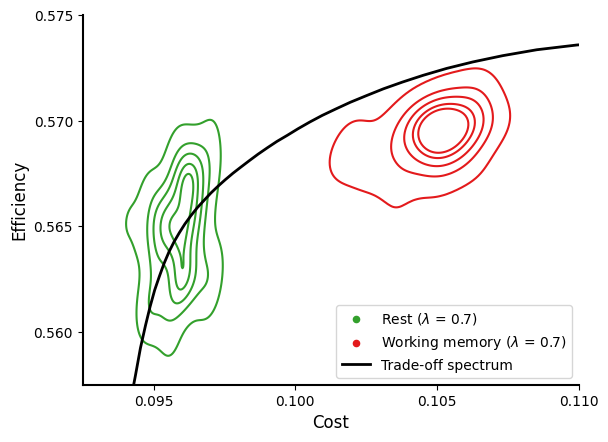

In [18]:
res_r = pd.read_csv('../results/fig05/graphical_res_HCP_MMP(distance_ridge).csv')
res_w = pd.read_csv('../results/fig05/graphical_res_HCP_WM_MMP(distance_ridge).csv')

res = {'task': [], 'cost': [], 'effi': []}
res['task'] += ['rest' for _ in range(100)]; res['cost'] += list(res_r[abs(res_r['lambda'] - 0.7) < 1e-3]['global_cost'].values); res['effi'] += list(res_r[abs(res_r['lambda'] - 0.7) < 1e-3]['global_effi'].values)
res['task'] += ['motor' for _ in range(100)]; res['cost'] += list(res_w[abs(res_w['lambda'] - 0.7) < 1e-3]['global_cost'].values); res['effi'] += list(res_w[abs(res_w['lambda'] - 0.7) < 1e-3]['global_effi'].values)
res = pd.DataFrame(res)
sns.kdeplot(data = res, x = 'cost', y = 'effi', hue = 'task', palette = [sns.color_palette('Paired')[3], sns.color_palette('Paired')[5]], levels = 6, legend = False)
plt.scatter(np.nan, np.nan, s = 20, color = sns.color_palette('Paired')[3], label = r'Rest ($\lambda$ = 0.7)')
plt.scatter(np.nan, np.nan, s = 20, color = sns.color_palette('Paired')[5], label = r'Working memory ($\lambda$ = 0.7)')
plt.plot(
    [np.mean(res_r[abs(res_r['lambda'] - lam) < 1e-3]['global_cost'].values) for lam in np.linspace(0.10, 0.98, 45)], 
    [np.mean(res_r[abs(res_r['lambda'] - lam) < 1e-3]['global_effi'].values) for lam in np.linspace(0.10, 0.98, 45)], 
    color = 'k', linewidth = 2, label = 'Trade-off spectrum'
)

plt.xlabel('Cost', fontsize = 12); plt.xlim(0.0925, 0.1100); plt.xticks([0.095, 0.100, 0.105, 0.110], fontsize = 10)
plt.ylabel('Efficiency', fontsize = 12); plt.ylim(0.5575, 0.5750); plt.yticks([0.560, 0.565, 0.570, 0.575], fontsize = 10)
plt.gca().spines['right'].set_visible(False); plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_linewidth(1.5); plt.gca().spines['bottom'].set_linewidth(1.5)
plt.legend(loc = 'lower right', fontsize = 10)

plt.show()